In [5]:
!pip install pandas openpyxl


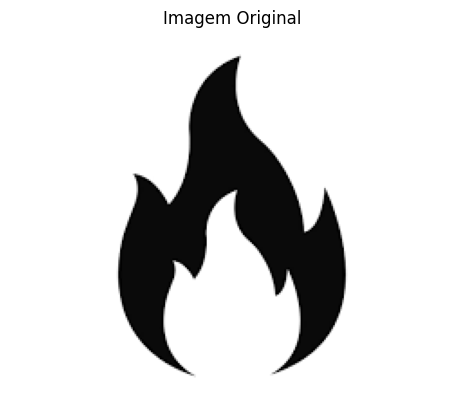

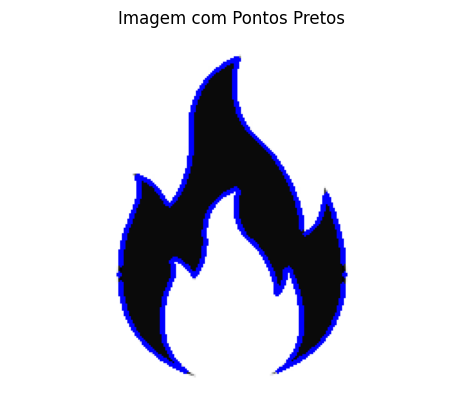

Coordenadas dos pontos pretos:
[[ 15 124]
 [ 15 125]
 [ 15 126]
 ...
 [188  96]
 [188  97]
 [188 148]]
Os pontos pretos foram exportados para o arquivo 'pontos_pretos.xlsx'.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# Carregar a imagem
image_path = 'images.png'  # Certifique-se de que a imagem foi carregada no Colab
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Verificar se a imagem foi carregada corretamente
if image is None:
    print("Erro ao carregar a imagem.")
else:
    # Mostrar a imagem original
    plt.imshow(image, cmap='gray')
    plt.title('Imagem Original')
    plt.axis('off')
    plt.show()

    # Obter as coordenadas dos pontos pretos
    pontos_pretos = np.column_stack(np.where(image == 0))

    # Mostrar a imagem com os pontos pretos destacados
    image_with_dots = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
    for point in pontos_pretos:
        cv2.circle(image_with_dots, (point[1], point[0]), 1, (0, 0, 255), -1)

    plt.imshow(image_with_dots)
    plt.title('Imagem com Pontos Pretos')
    plt.axis('off')
    plt.show()

    # Exibir a matriz de pontos (x, y)
    print("Coordenadas dos pontos pretos:")
    print(pontos_pretos)

    # Exportar para arquivo Excel
    df = pd.DataFrame(pontos_pretos, columns=['Y', 'X'])
    excel_file = 'pontos_pretos.xlsx'
    df.to_excel(excel_file, index=False)
    print("Os pontos pretos foram exportados para o arquivo 'pontos_pretos.xlsx'.")

    # Fazer o download do arquivo Excel
    files.download(excel_file)
